# 01 · Datos y ETL secuencial en C++

**Proyecto:** ETL distribuido de COVID-19 e influenza, México.  
**Objetivo del curso:** programación paralela en C/C++.  
**Integración:** conserva los avances originales y añade un motor común C++17.

El CSV se extrae y explora; el ejecutable C++ lee, infiere columnas numéricas, limpia y exporta. Python se usa para exploración, validación y análisis. Los notebooks Python originales se conservan como referencia de las reglas, sin confundirlos con la implementación C++.


## 1. Entorno y archivo de entrada

La entrada real es `datos/COVID19MEXICO.csv`. El hash identifica exactamente el archivo evaluado. Todos los escenarios usan el mismo ejecutable C++ compilado en la imagen OpenMP existente, con optimización `-O3` y soporte OpenMP.


In [1]:
from pathlib import Path
import sys, json
import pandas as pd
from PIL import Image

ROOT = Path.cwd()
if not (ROOT / "cpp/etl.cpp").exists():
    raise RuntimeError("Abrir y ejecutar el notebook desde la carpeta del proyecto")
sys.path.insert(0, str(ROOT / "scripts"))
OUT = ROOT / "resultados_experimentos"
entorno = json.loads((OUT / "entorno.json").read_text())
mediciones = pd.read_csv(OUT / "mediciones.csv")
resumen = pd.read_csv(OUT / "resumen_rendimiento.csv")
pd.set_option("display.max_columns", 20)
pd.set_option("display.float_format", lambda x: f"{x:.6f}")
print("Dataset SHA-256:", entorno["dataset_sha256"])
print("Compilación:", entorno["compilacion"])
print("Kubernetes:", entorno["kubernetes"])


Dataset SHA-256: ca65e96d26e1e7cb58b0b5ec1c642fbcb24926684077cbee5cf2864251ce9728
Compilación: g++ 13.3.0; -std=c++17 -O3 -Wall -Wextra -Wpedantic -fopenmp
Kubernetes: v1.34.13+k3s1


In [2]:
original = pd.read_csv(ROOT / "datos/COVID19MEXICO.csv", encoding="utf-8-sig", low_memory=False)
print(f"Entrada: {len(original):,} filas × {len(original.columns)} columnas")
display(original.head(3))
display(pd.DataFrame({"tipo": original.dtypes.astype(str), "nulos": original.isna().sum()}))
print("Duplicados exactos:", int(original.duplicated().sum()))
print("ID repetidos:", int(original.ID_REGISTRO.duplicated().sum()))

Entrada: 108,733 filas × 42 columnas


,FECHA_ACTUALIZACION,ID_REGISTRO,ORIGEN,SECTOR,ENTIDAD_UM,SEXO,ENTIDAD_NAC,ENTIDAD_RES,MUNICIPIO_RES,TIPO_PACIENTE,...,RESULTADO_PCR,RESULTADO_PCR_COINFECCION,TOMA_MUESTRA_ANTIGENO,RESULTADO_ANTIGENO,CLASIFICACION_FINAL_COVID,CLASIFICACION_FINAL_FLU,MIGRANTE,PAIS_NACIONALIDAD,PAIS_ORIGEN,UCI
0,2026-11-02,g829cab,1,12,11,2,11,11,15,1,...,997,997,2,97,6,6,99,México,97,97
1,2026-11-02,gc633cc,1,8,9,2,7,9,12,1,...,997,997,2,97,6,6,99,México,97,97
2,2026-11-02,gad762a,1,4,30,2,30,30,87,2,...,3,998,2,97,7,3,99,México,97,2


,tipo,nulos
FECHA_ACTUALIZACION,str,0
ID_REGISTRO,str,0
ORIGEN,int64,0
SECTOR,int64,0
ENTIDAD_UM,int64,0
SEXO,int64,0
ENTIDAD_NAC,int64,0
ENTIDAD_RES,int64,0
MUNICIPIO_RES,int64,0
TIPO_PACIENTE,int64,0


Duplicados exactos: 0
ID repetidos: 0


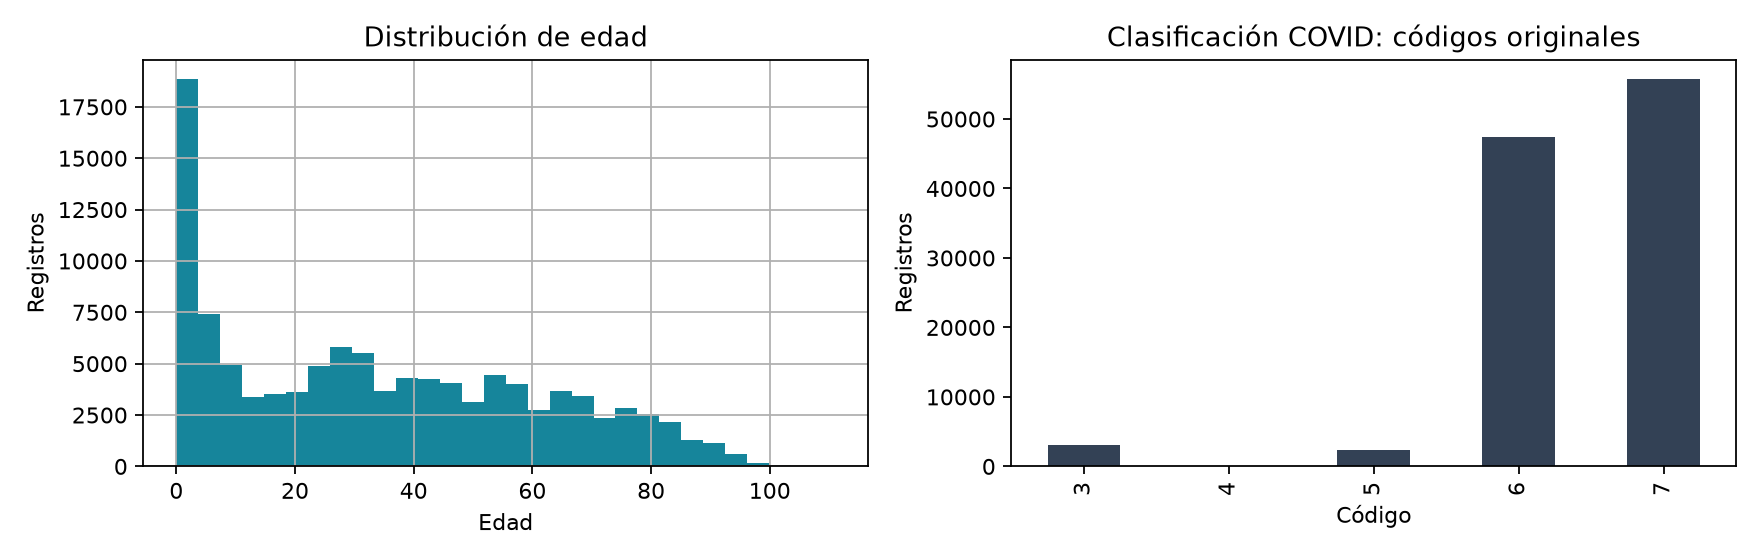

In [3]:
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
original.EDAD.hist(bins=30, ax=axes[0], color="#16859b")
axes[0].set(title="Distribución de edad", xlabel="Edad", ylabel="Registros")
original.CLASIFICACION_FINAL_COVID.value_counts().sort_index().plot.bar(ax=axes[1], color="#334155")
axes[1].set(title="Clasificación COVID: códigos originales", xlabel="Código", ylabel="Registros")
fig.tight_layout()
fig.savefig(OUT / "exploracion_datos.png", dpi=160)
plt.close(fig)
display(Image.open(OUT / "exploracion_datos.png"))

## 2. Reglas conservadas de la versión original

1. Normalizar encabezados y conservar el esquema.
2. Eliminar duplicados exactos y después identificadores repetidos, conservando la primera aparición.
3. Convertir fechas ISO válidas; el marcador `9999-99-99` y las fechas inválidas quedan vacíos.
4. Convertir `EDAD` a número y marcar como faltantes los valores fuera de 0–120, sin eliminar filas.
5. Recortar espacios de los textos y exportar CSV UTF-8.

El lector C++ admite BOM, CRLF, comillas escapadas y campos multilínea. La inferencia numérica previa conserva el comportamiento de pandas para el esquema real (por ejemplo, `015` en una columna numérica se representa como `15`). El validador de fechas está definido para el formato ISO de esta fuente; no pretende admitir cualquier formato de fecha externo.

Los códigos clínicos se conservan sin asignar interpretaciones que no estén documentadas en su catálogo.


In [4]:
print((ROOT / "Makefile").read_text())
print("Comando de referencia:")
print("bin/etl --input datos/COVID19MEXICO.csv --output resultados/limpio.csv --audit resultados/auditoria.json --mode seq")
archivo = OUT / "ejecuciones/cpp_secuencial_05/auditoria.json"
display(pd.DataFrame([json.loads(archivo.read_text())]))

CXX ?= g++
CXXFLAGS ?= -std=c++17 -O3 -Wall -Wextra -Wpedantic -fopenmp

.PHONY: all clean
all: bin/etl

bin/etl: cpp/etl.cpp
	@mkdir -p bin
	$(CXX) $(CXXFLAGS) $< -o $@

clean:
	rm -f bin/etl

Comando de referencia:
bin/etl --input datos/COVID19MEXICO.csv --output resultados/limpio.csv --audit resultados/auditoria.json --mode seq


,implementacion,filas_dataset,filas_entrada,duplicados_exactos_eliminados,duplicados_id_eliminados,edades_invalidas_convertidas_a_nulo,filas_salida,hilos_solicitados,hilos_utilizados,particion,particiones,lectura_segundos,preparacion_global_segundos,transformacion_filas_segundos,etl_segundos,escritura_segundos,total_segundos,openmp_version
0,C++17/seq,108733,108733,0,0,0,108733,1,1,0,1,0.739990,0.161649,0.053209,0.214858,0.124100,1.078949,201511


## 3. Validación y productos

Se ejecutó la función original del notebook 01 para obtener una referencia independiente. Se compararon valores, columnas, orden y nulos; al recargar CSV se admiten tipos numéricos equivalentes. Además, los hashes de todas las salidas C++ deben coincidir exactamente entre sí.

Las pruebas sintéticas cubren duplicados entre particiones, fechas no válidas, edades fuera de rango, campos con comillas/saltos de línea y errores de entrada.


In [5]:
validacion = json.loads((OUT / "ejecuciones/cpp_secuencial_05/validacion.json").read_text())
display(pd.DataFrame([validacion]))
assert mediciones.validado.all()
assert mediciones.salida_sha256.nunique() == 1
print("Las 40 ejecuciones medidas coinciden con la referencia y entre sí.")
for ruta in sorted((OUT / "resumenes").glob("*.csv")):
    print(ruta.name)
    display(pd.read_csv(ruta))

,filas,columnas,coincide_referencia_python,sha256_csv,auditoria_coincide_referencia
0,108733,42,True,7ac454c8bc4420dd7f4d36fd168820f1b2e5f608629d95...,True


Las 40 ejecuciones medidas coinciden con la referencia y entre sí.
resumen_clasificacion_covid.csv


,codigo,registros
0,3,3079
1,4,32
2,5,2399
3,6,47479
4,7,55744


resumen_clasificacion_influenza.csv


,codigo,registros
0,3,7873
1,4,32
2,5,2399
3,6,47479
4,7,50950


resumen_mensual_ingresos.csv


,mes_ingreso,registros
0,2026-01,18154
1,2026-02,17064
2,2026-03,13289
3,2026-04,7441
4,2026-05,6933
5,2026-06,7514
6,2026-07,9761
7,2026-08,7530
8,2026-09,10017
9,2026-10,10976


## Resultado del avance 1

El ETL secuencial C++ constituye la línea base de la evaluación. Los resúmenes descriptivos se generan desde su conjunto limpio y se guardan junto con las auditorías. Los tiempos de lectura, transformación y escritura quedan separados para la parte 4.


## Fuentes técnicas

- [OpenMP: distribución de iteraciones](https://www.openmp.org/spec-html/5.2/openmpse66.html).
- [GCC: compilación con `-fopenmp`](https://gcc.gnu.org/projects/gomp/).
- [Kubernetes: Jobs paralelos e indexados](https://kubernetes.io/docs/concepts/workloads/controllers/job/).
- [Cornell: Ley de Amdahl](https://cvw.cac.cornell.edu/parallel/efficiency/amdahls-law).

Los resultados numéricos proceden exclusivamente de los CSV, auditorías y registros de esta entrega.
